In [96]:
import ast
import heapq
import itertools
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque
import math

In [97]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded.keys()))

print("Uploaded file:", filename)

Saving Environment.txt to Environment (4).txt
Uploaded file: Environment (4).txt


In [98]:
def parse_coordinates(text):
    coordinates = ast.literal_eval(text.strip())

    # Convert a single coordinate into a list
    if (
        isinstance(coordinates, tuple)
        and len(coordinates) == 2
        and all(isinstance(x, int) for x in coordinates)
    ):
        coordinates = [coordinates]

    return [tuple(point) for point in coordinates]


def load_environment(filename):

    with open(filename, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    # Read grid dimensions
    rows, cols = map(int, lines[0].split(","))

    # Read obstacle information
    obstacle_count = int(lines[1])
    obstacles = set(parse_coordinates(lines[2]))

    # Read dirty location information
    dirty_count = int(lines[3])
    dirty_locations = parse_coordinates(lines[4])

    # Read charging station
    charging_station = parse_coordinates(lines[5])[0]

    grid = {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_locations": dirty_locations,
        "charging_station": charging_station
    }

    return grid

In [99]:
grid = load_environment(filename)

print("Grid Size:", grid["rows"], "x", grid["cols"])
print("Obstacles:", grid["obstacles"])
print("Dirty Locations:", grid["dirty_locations"])
print("Charging Station:", grid["charging_station"])

Grid Size: 8 x 8
Obstacles: {(2, 4), (6, 5), (0, 0), (6, 1), (7, 3), (0, 5), (3, 6), (3, 2)}
Dirty Locations: [(5, 3), (4, 4), (1, 2), (6, 7)]
Charging Station: (0, 7)


In [100]:
def validate_environment(grid):

    rows = grid["rows"]
    cols = grid["cols"]
    obstacles = grid["obstacles"]
    dirty = grid["dirty_locations"]
    charging = grid["charging_station"]

    errors = []

    # Check grid dimensions
    if rows < 8 or cols < 8:
        errors.append("Grid must be at least 8x8.")

    # Check obstacle count
    if len(obstacles) < 6:
        errors.append("At least 6 obstacles are required.")

    # Check dirty locations
    if len(dirty) < 4:
        errors.append("At least 4 dirty locations are required.")

    # Check duplicate coordinates
    if len(dirty) != len(set(dirty)):
        errors.append("Duplicate dirty locations found.")

    # Check coordinate boundaries
    all_positions = obstacles | set(dirty) | {charging}

    for r, c in all_positions:
        if not (0 <= r < rows and 0 <= c < cols):
            errors.append(f"Coordinate {(r, c)} is outside the grid.")

    # Check overlapping positions
    if obstacles.intersection(dirty):
        errors.append("An obstacle overlaps a dirty location.")

    if charging in obstacles:
        errors.append("Charging station overlaps an obstacle.")

    if charging in dirty:
        errors.append("Charging station overlaps a dirty location.")

    # Check every dirty location is reachable
    for location in dirty:
        if not is_reachable(charging, location, grid):
            errors.append(f"Dirty location {location} is unreachable.")

    if errors:
        print("Environment is INVALID:")
        for error in errors:
            print("-", error)
        return False

    print("Environment is VALID!")
    return True

In [101]:
def is_reachable(start, goal, grid):

    queue = deque([start])
    visited = {start}

    while queue:

        current = queue.popleft()

        if current == goal:
            return True

        for next_state, action, cost in get_successors(current, grid):

            if next_state not in visited:
                visited.add(next_state)
                queue.append(next_state)

    return False

In [102]:
def display_grid(grid):

    rows = grid["rows"]
    cols = grid["cols"]

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)

    # Draw grid cells
    for r in range(rows):
        for c in range(cols):

            color = "white"
            label = ""

            if (r, c) in grid["obstacles"]:
                color = "gray"
                label = "X"

            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                index = grid["dirty_locations"].index((r, c))
                label = f"D{index + 1}"

            elif (r, c) == grid["charging_station"]:
                color = "lightgreen"
                label = "C"

            rect = plt.Rectangle(
                (c, r), 1, 1,
                facecolor=color,
                edgecolor="black"
            )

            ax.add_patch(rect)

            ax.text(
                c + 0.5,
                r + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold"
            )

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_xticklabels(range(cols))
    ax.set_yticklabels(range(rows))

    ax.set_title("Vacuum Cleaning Robot Environment")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

    plt.grid(False)
    plt.show()

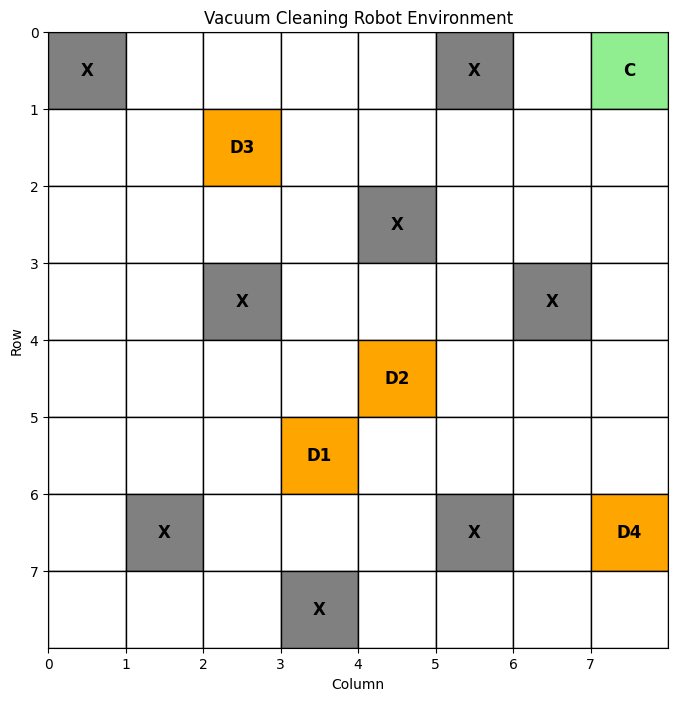

In [103]:
display_grid(grid)

In [104]:
def get_successors(state, grid):

    row, col = state

    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    successors = []

    for dr, dc, action in moves:

        new_row = row + dr
        new_col = col + dc

        next_state = (new_row, new_col)

        # Check grid boundaries and obstacles
        if (
            0 <= new_row < grid["rows"]
            and 0 <= new_col < grid["cols"]
            and next_state not in grid["obstacles"]
        ):

            successors.append((next_state, action, 1))

    return successors

In [105]:
environment_valid = validate_environment(grid)

Environment is VALID!


In [106]:
def goal_test(state, goal_state):

    return state == goal_state

In [107]:
def path_cost(path):

    if not path:
        return 0

    return len(path) - 1

In [108]:
example_path = [(0, 7), (1, 7), (1, 6), (2, 6)]

print("Path Cost:", path_cost(example_path))

Path Cost: 3


In [109]:
def heuristic(state, goal_state):

    row1, col1 = state
    row2, col2 = goal_state

    return abs(row1 - row2) + abs(col1 - col2)

In [110]:
print(heuristic((0, 7), (5, 3)))

9


## A* Search

A* is an informed search algorithm. It combines the actual cost already
travelled with a heuristic estimate of the cost still remaining:

    f(n) = g(n) + h(n)

- g(n) is the actual path cost from the start to cell n (each move costs 1).
- h(n) is the Manhattan distance from cell n to the goal, using the
  heuristic() function defined earlier.
- f(n) is the estimated total cost of a path through n.

The frontier is a priority queue (min-heap) ordered by f(n). A g_score
dictionary stores the cheapest known cost to reach each cell, and a parent
dictionary records how each cell was reached so the final path can be rebuilt.

The algorithm returns:
- The path from the start to the goal.
- The total path cost.
- The number of nodes expanded.

If no path exists, it returns None, an infinite cost and the number of
nodes expanded before the frontier became empty.

### Working Principle of A*

1. Place the start position in the priority queue with f = g + h, where g = 0.
2. Remove the cell with the lowest f value from the queue.
3. If it was already expanded with a cheaper cost, skip it (stale entry).
4. If it is the goal, rebuild the path using the parent dictionary.
5. Otherwise, count it as expanded and generate its valid successors.
6. For each successor, compute new_g = g(current) + step cost. If this is
   cheaper than any known cost for that cell, update g_score and parent, and
   push the cell into the queue with f = new_g + h.
7. Repeat until the goal is found or the queue is empty.

Manhattan distance is admissible here because the robot moves only UP, DOWN,
LEFT or RIGHT with cost 1, so it never overestimates the true cost. It is also
consistent. Therefore A* is complete and optimal in this environment, and it
finds paths with the same cost as BFS while usually expanding fewer cells.

Ties in f are broken by the smaller h (the cell closer to the goal), then by
insertion order. Nodes are counted when they are expanded, after the goal
test. This is the same counting rule used in BFS and GBFS, so the results can
be compared fairly.

In [111]:
def A_star_search(start, goal, grid):
    """A* Search using f(n) = g(n) + h(n) with Manhattan distance.
    Returns (path, cost, nodes_expanded).
    Returns (None, inf, nodes_expanded) if no path exists."""

    counter = itertools.count()    # tie-breaker for equal priorities
    start_h = heuristic(start, goal)

    # Priority queue entries: (f, h, insertion_order, state)
    frontier = [(start_h, start_h, next(counter), start)]
    g_score = {start: 0}           # cheapest known cost to each cell
    parent = {start: None}         # parent links for path reconstruction
    closed = set()                 # cells already expanded
    nodes_expanded = 0

    while frontier:
        f, h, _, current = heapq.heappop(frontier)

        # Skip stale entries (a cheaper route was already expanded)
        if current in closed:
            continue

        # Goal test
        if goal_test(current, goal):
            path = []
            state = current
            while state is not None:
                path.append(state)
                state = parent[state]
            path.reverse()
            return path, path_cost(path), nodes_expanded

        # Expand the node
        closed.add(current)
        nodes_expanded += 1

        for next_state, action, step_cost in get_successors(current, grid):
            new_g = g_score[current] + step_cost

            if next_state not in g_score or new_g < g_score[next_state]:
                g_score[next_state] = new_g
                parent[next_state] = current
                new_h = heuristic(next_state, goal)
                heapq.heappush(
                    frontier,
                    (new_g + new_h, new_h, next(counter), next_state)
                )

    # No path found
    return None, float("inf"), nodes_expanded

### Testing A* on All Dirty Locations

The robot starts at the charging station and A* finds a path to each
dirty location separately. For every search, the path, total cost and
number of nodes expanded are displayed.

In [112]:
start = grid["charging_station"]

if environment_valid:
    for index, goal in enumerate(grid["dirty_locations"]):
        path, cost, expanded = A_star_search(start, goal, grid)

        print(f"\nD{index + 1}: {goal}")
        print("Path:", path)
        print("Total Cost:", cost)
        print("Nodes Expanded:", expanded)


D1: (5, 3)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (5, 6), (5, 5), (5, 4), (5, 3)]
Total Cost: 9
Nodes Expanded: 9

D2: (4, 4)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (4, 6), (4, 5), (4, 4)]
Total Cost: 7
Nodes Expanded: 7

D3: (1, 2)
Path: [(0, 7), (1, 7), (1, 6), (1, 5), (1, 4), (1, 3), (1, 2)]
Total Cost: 6
Nodes Expanded: 6

D4: (6, 7)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7)]
Total Cost: 6
Nodes Expanded: 6


### Edge Cases

Two special cases are tested:
1. The start and goal are the same cell. A* should return a one-cell
   path with cost 0 and no nodes expanded.
2. The goal is surrounded by obstacles. A* should return no path and an
   infinite cost after exhausting all reachable cells.

In [113]:
# Case 1: start equals goal
print("Start equals goal:")
print(A_star_search(start, start, grid))

# Case 2: unreachable goal (goal enclosed by obstacles)
test_grid = {
    "rows": 8,
    "cols": 8,
    "obstacles": {(2, 3), (3, 2), (3, 4), (4, 3)},
    "dirty_locations": [(3, 3)],
    "charging_station": (0, 0),
    "declared_obstacle_count": 4,
    "declared_dirty_count": 1
}

path, cost, expanded = A_star_search((0, 0), (3, 3), test_grid)
print("\nUnreachable goal:")
print("Path:", path)
print("Cost:", cost)
print("Nodes Expanded:", expanded)

Start equals goal:
([(0, 7)], 0, 0)

Unreachable goal:
Path: None
Cost: inf
Nodes Expanded: 59


In [114]:
print("=" * 50)
print("FINAL A* RESULTS")
print("=" * 50)

for index, goal in enumerate(grid["dirty_locations"]):
    path, cost, expanded = A_star_search(
        grid["charging_station"], goal, grid
    )
    print(f"\nDirty Location D{index + 1}: {goal}")
    if path is not None:
        print("Status: SUCCESS")
        print("Path Cost:", cost)
        print("Nodes Expanded:", expanded)
    else:
        print("Status: FAILURE")
        print("No valid path exists.")

FINAL A* RESULTS

Dirty Location D1: (5, 3)
Status: SUCCESS
Path Cost: 9
Nodes Expanded: 9

Dirty Location D2: (4, 4)
Status: SUCCESS
Path Cost: 7
Nodes Expanded: 7

Dirty Location D3: (1, 2)
Status: SUCCESS
Path Cost: 6
Nodes Expanded: 6

Dirty Location D4: (6, 7)
Status: SUCCESS
Path Cost: 6
Nodes Expanded: 6


### Visualization of A* Paths and Explored Cells

This section provides reusable visualization functions:

- visualize_A_star(): draws one A* search. The final path is shown as a blue
  line, and the cells expanded during the search are shaded light blue.
- visualize_all_A_star(): draws the A* path from the charging station to
  every dirty location, one panel per location, with the cost and number
  of expanded nodes in each title.

Color legend:
- Gray (X): obstacle
- Orange (D1 to D4): dirty location
- Light green (C): charging station
- Light blue: cell expanded by A*
- Blue line: final path found

The shaded region is small and stays close to the path because the
Manhattan heuristic guides A* directly towards the goal.

In [115]:
import math

def A_star_expanded_cells(start, goal, grid):
    """Returns the list of cells A* expands, in order.
    Uses the same logic as A_star_search, so its length
    equals nodes_expanded."""
    counter = itertools.count()
    start_h = heuristic(start, goal)
    frontier = [(start_h, start_h, next(counter), start)]
    g_score = {start: 0}
    closed = set()
    expanded = []

    while frontier:
        f, h, _, current = heapq.heappop(frontier)
        if current in closed:
            continue
        if goal_test(current, goal):
            break
        closed.add(current)
        expanded.append(current)
        for next_state, action, step_cost in get_successors(current, grid):
            new_g = g_score[current] + step_cost
            if next_state not in g_score or new_g < g_score[next_state]:
                g_score[next_state] = new_g
                new_h = heuristic(next_state, goal)
                heapq.heappush(
                    frontier,
                    (new_g + new_h, new_h, next(counter), next_state)
                )

    return expanded


def draw_A_star_on_axis(ax, grid, path, explored, title):
    rows, cols = grid["rows"], grid["cols"]
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")

    for r in range(rows):
        for c in range(cols):
            color, label = "white", ""
            if (r, c) in grid["obstacles"]:
                color, label = "gray", "X"
            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                label = f"D{grid['dirty_locations'].index((r, c)) + 1}"
            elif (r, c) == grid["charging_station"]:
                color, label = "lightgreen", "C"
            elif (r, c) in explored:
                color = "lightblue"

            ax.add_patch(plt.Rectangle((c, r), 1, 1,
                         facecolor=color, edgecolor="black"))
            if label:
                ax.text(c + 0.5, r + 0.5, label, ha="center",
                        va="center", fontsize=10, fontweight="bold")

    if path:
        xs = [col + 0.5 for row, col in path]
        ys = [row + 0.5 for row, col in path]
        ax.plot(xs, ys, color="blue", linewidth=2.5, marker="o",
                markersize=5)

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")


def visualize_A_star(grid, start, goal, show_explored=True):
    """Runs A* from start to goal and draws the result."""
    path, cost, expanded = A_star_search(start, goal, grid)

    if path is None:
        print(f"No path from {start} to {goal}. "
              f"Nodes expanded: {expanded}")
        return

    explored = set(A_star_expanded_cells(start, goal, grid)) \
        if show_explored else set()

    fig, ax = plt.subplots(figsize=(7, 7))
    draw_A_star_on_axis(
        ax, grid, path, explored,
        f"A*: {start} to {goal} | Cost: {cost} | Expanded: {expanded}"
    )
    plt.show()


def visualize_all_A_star(grid, show_explored=True):
    """Draws the A* path from the charging station to every dirty
    location, one panel per location."""
    start = grid["charging_station"]
    n = len(grid["dirty_locations"])
    n_cols = 2
    n_rows = math.ceil(n / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(7 * n_cols, 7 * n_rows))
    axes = axes.flatten() if n > 1 else [axes]

    for i, goal in enumerate(grid["dirty_locations"]):
        path, cost, expanded = A_star_search(start, goal, grid)
        explored = set(A_star_expanded_cells(start, goal, grid)) \
            if (show_explored and path) else set()
        draw_A_star_on_axis(
            axes[i], grid, path, explored,
            f"D{i + 1} {goal} | Cost: {cost} | Expanded: {expanded}"
        )

    for j in range(n, len(axes)):      # hide unused panels
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

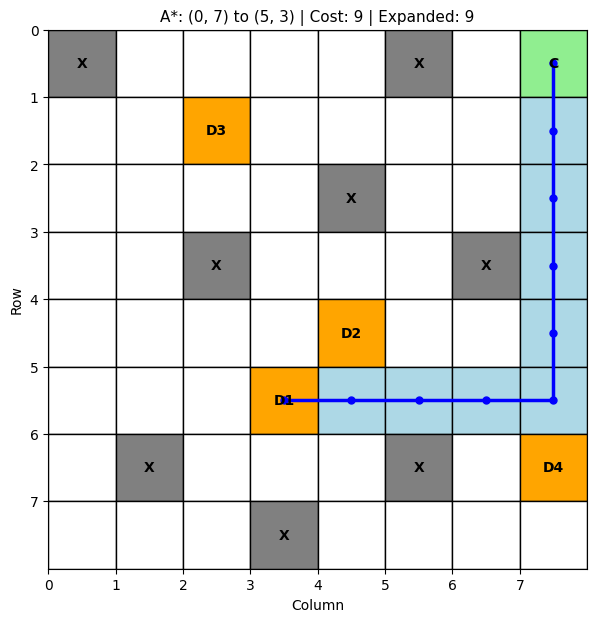

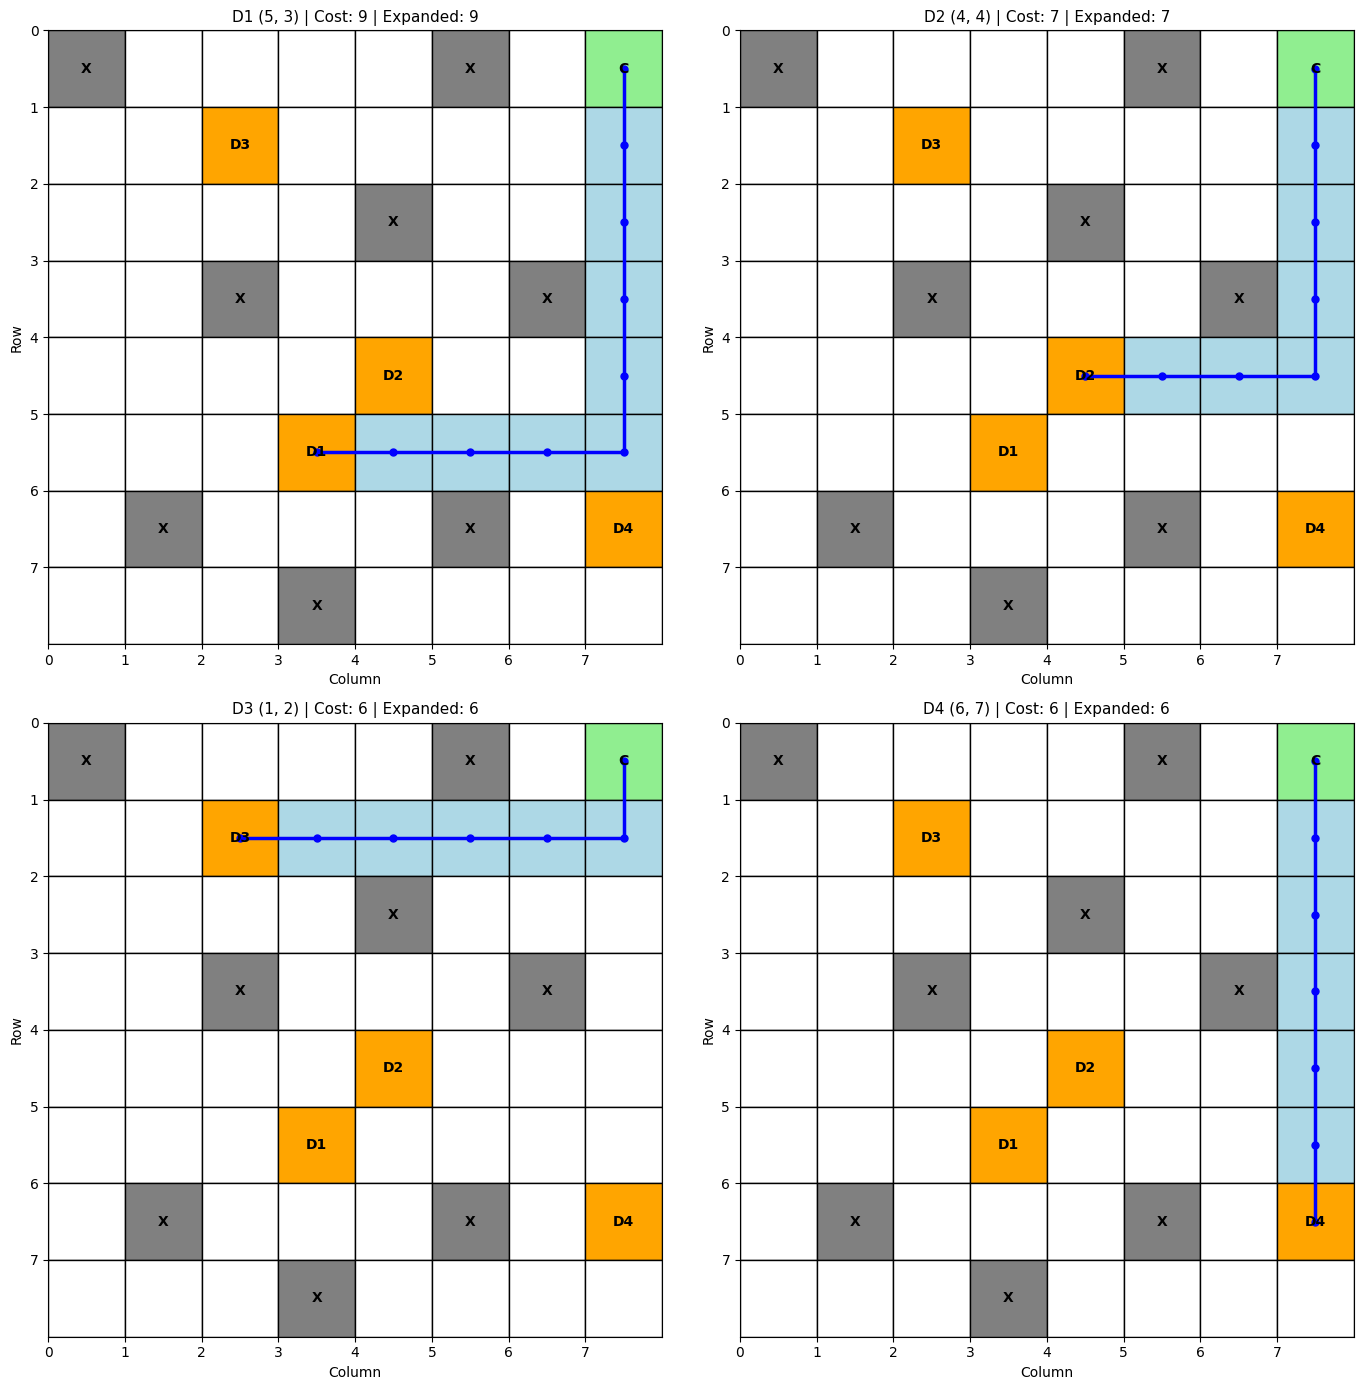

In [116]:
start = grid["charging_station"]

# One search, with explored cells shaded
visualize_A_star(grid, start, grid["dirty_locations"][0])

# All dirty locations in one figure
visualize_all_A_star(grid)